# Differential equations 1: First-order equations, slope fields and equilibria

*Learning path: differential equations, part 1 of 8.* [Index](README.md) · Next: [Linear first-order equations](02-linear-first-order.ipynb)

A fish population grows fast while it is small and levels off when the lake is full. A tank drains, fast while it is
full and slowly at the end. A cup of coffee cools. Each sentence describes a **rate of change** in terms of the
present state, $y' = f(x, y)$, and asks for the function $y$ itself. This lesson shows three ways to answer: draw the
slopes and follow them, solve with a formula when the equation separates, and read the long-term behaviour straight
from $f$ without solving at all.

**Who this is for.** Students starting a first course on differential equations. You should know derivatives and
integrals of one variable ([foundations 7](../foundations/07-calculus.ipynb)); a first look at
[foundations 8](../foundations/08-differential-equations.ipynb) helps but is not needed.

**What you will be able to do afterwards:**

1. draw a slope field and sketch solution curves from it;
2. solve a separable equation $y' = f(x)\,g(y)$ by hand, and check the answer by substituting it;
3. solve and interpret the logistic equation;
4. find the equilibria of $y' = f(y)$ and decide from $f$ which are stable;
5. recognise solutions that blow up in finite time, and an equation whose solution is not unique.

Plan about an hour. Each section ends with a **Try this** for the cell below it; exercises, hints and answers are at
the end.

## 1. Slope fields: seeing solutions before solving

The equation $y' = x - y$ says: at the point $(x, y)$, a solution passes with slope $x - y$. Draw a short segment
with that slope at many points and you get the **slope field**. Every solution is a curve that is tangent to the
segments everywhere. `fieldplot([1, f], x, ..., y, ...)` draws it: the arrow $[1, f]$ moves 1 to the right and $f$ up,
so its slope is $f$. `window(p, x0, x1, y0, y1)` keeps the picture to the square we care about.

`dsolve` finds the formula, with a constant `C1` for the family of solutions:

In [1]:
sol = dsolve(d(y, x) == x - y, y, x)

exp(-x)*C1+x-1

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

Check it by substitution, which is always possible and always worth it: $y = C_1e^{-x} + x - 1$ gives
$y' = -C_1e^{-x} + 1$, and $x - y = -C_1e^{-x} + 1$. Equal. Now the picture, with three members of the family:

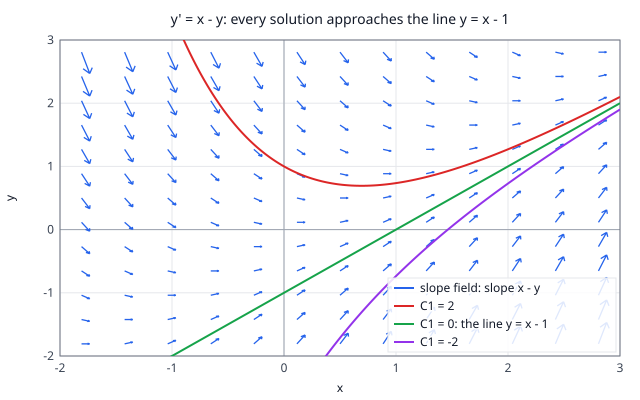

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [2]:
ya = subs(sol, C1, 2);
yb = subs(sol, C1, 0);
yc = subs(sol, C1, -2);
p = show(fieldplot([1, x - y], x, -2, 3, y, -2, 3, 13), plot(ya, yb, yc, x, -2, 3));
p = legend(p, "slope field: slope x - y", "C1 = 2", "C1 = 0: the line y = x - 1", "C1 = -2");
p = window(p, -2, 3, -2, 3);
labels(title(p, "y' = x - y: every solution approaches the line y = x - 1"), "x", "y")

The field already tells the story: above the line $y = x - 1$ the slopes are smaller than 1 and solutions fall
towards it, below it they rise towards it. The factor $e^{-x}$ in the formula says how fast.

**Try this.** Draw the slope field of $y' = y - x$. Which line is still a solution? Do the other solutions approach it
or run away?

## 2. Separable equations

When the right-hand side splits as a function of $x$ times a function of $y$,

$$\frac{dy}{dx} = f(x)\,g(y),$$

divide by $g(y)$ and integrate both sides:

$$\int \frac{dy}{g(y)} = \int f(x)\,dx + C.$$

Example: $y' = xy$. Then $\int dy/y = \int x\,dx$, so $\log|y| = x^2/2 + C$ and $y = C_1e^{x^2/2}$ (the constant
$\pm e^C$ is renamed $C_1$). `dsolve` does the same steps, and with `explain` on its note shows them:

In [3]:
dsolve(d(y, x) == x*y, y, x)
dsolve(d(y, x) == -x/y, y, x, 0, 2)

exp(x^2/2)*C1

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

sqrt(4-x^2)

> Separable: y' = f(x) g(y) with f(x) = x and g(y) = -1/y. Divide by g(y) and integrate both sides: ∫ dy/g(y) = ∫ f(x) dx, so -y^2/2 = x^2/2 + C1. The start value y(0) = 2 fixes C1 = -2.

The second equation has slopes perpendicular to the radius vector $[x, y]$, so its solutions are circles:
$y = \sqrt{4 - x^2}$ is the upper half of the circle of radius 2 through the start point $(0, 2)$. It stops at
$x = \pm2$, where the slope becomes vertical: a solution need not live for all $x$.

**A draining tank.** Water leaves through a hole at the bottom at a speed $\sqrt{2gh}$ (Torricelli), so the height
obeys $h' = -k\sqrt{h}$. With $k = 1/2$ and $h(0) = 4$:

In [4]:
h = dsolve(d(h, t) == -sqrt(h)/2, h, t, 0, 4)

(t-8)^2/16

> Separable: h' = f(t) g(h) with f(t) = 1 and g(h) = -sqrt(h)/2. Divide by g(h) and integrate both sides: ∫ dh/g(h) = ∫ f(t) dt, so -4*sqrt(h) = t + C1. The start value h(0) = 4 fixes the constant: C1 = -8.

So $h = (8 - t)^2/16$ until the tank is empty at $t = 8$; after that $h = 0$. A tank empties in finite time, unlike
the exponential decay $y' = -ky$, which never reaches 0. The difference is that $\sqrt{h}$ falls much more slowly than
$h$ near 0, so the flow does not slow down enough.

One warning: dividing by $g(y)$ throws away the **constant solutions** where $g(y) = 0$. For $y' = xy$ that is
$y = 0$, which is the member $C_1 = 0$ of the family. Not always: see section 5.

**Try this.** Solve $y' = y\cos x$ with $y(0) = 1$ by hand, then check with `dsolve`.

In [5]:
dsolve(d(y, x) == y*cos(x), y, x, 0, 1)

exp(sin(x))

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

## 3. The logistic equation

A population $P$ in a lake with room for $K$ fish grows at rate $r$ while small, and the growth stops as $P$ nears
$K$:

$$P' = rP\left(1 - \frac{P}{K}\right).$$

It is separable. With $r = 1/2$ and $K = 1000$ and 100 fish at the start:

In [6]:
fish = dsolve(d(P, t) == P*(1 - P/1000)/2, P, t, 0, 100)

1000*exp(t/2)/(exp(t/2)+9)

> Separable: P' = f(t) g(P) with f(t) = 1 and g(P) = P*(1-P/1000)/2. Divide by g(P) and integrate both sides: ∫ dP/g(P) = ∫ f(t) dt, so 2*(log(P)-log(P-1000)) = t + C1. Dividing by g(P) loses the constant solutions where g(P) = 0: P = 0, P = 1000. The start value P(0) = 100 fixes the constant: C1 = -1/9.

That is $P(t) = \dfrac{1000\,e^{t/2}}{e^{t/2} + 9}$. By hand: partial fractions give
$\dfrac{1}{P(1 - P/K)} = \dfrac1P + \dfrac{1}{K - P}$, so $\log P - \log(K - P) = rt + C$, and solving for $P$ gives
$P = K/(1 + Ae^{-rt})$ with $A = (K - P_0)/P_0 = 9$. Different starts, below and above $K$:

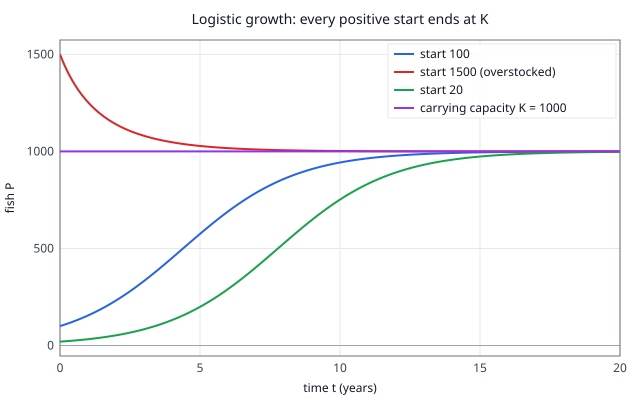

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
fish2 = dsolve(d(P, t) == P*(1 - P/1000)/2, P, t, 0, 1500);
fish3 = dsolve(d(P, t) == P*(1 - P/1000)/2, P, t, 0, 20);
p = plot(fish, fish2, fish3, 1000, t, 0, 20);
p = legend(p, "start 100", "start 1500 (overstocked)", "start 20", "carrying capacity K = 1000");
labels(title(p, "Logistic growth: every positive start ends at K"), "time t (years)", "fish P")

The curve from 100 is the famous S: it is steepest at $P = K/2 = 500$, where $P(1 - P/K)$ is largest. From 1500 the
population falls back to $K$. Nothing ever crosses the line $P = K$: two solutions of $y' = f(y)$ cannot cross,
because at the crossing point they would have to have the same slope and then be the same solution.

**Try this.** When does the population that starts at 100 reach 900? Solve `fish == 900` for `t` (the answer is
$8\log 3 = 4\log 9$, about 8.8 years).

In [8]:
solve(fish == 900, t)

8*log(3)

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

## 4. Equilibria and stability, without solving

For an **autonomous** equation $y' = f(y)$ (no $x$ on the right), the long run can be read from the graph of $f$:

* where $f(y) = 0$, $y$ stays put: an **equilibrium**;
* where $f(y) > 0$, $y$ increases; where $f(y) < 0$, it decreases.

An equilibrium is **stable** when nearby solutions move towards it: $f$ changes from $+$ to $-$ there, which (when
$f' \ne 0$) means $f'(y^*) < 0$. Fishing at a constant rate $h$ changes the logistic equation (with $r = K = 1$) to
$P' = P(1 - P) - h$:

In [9]:
f = P*(1 - P) - 3/16;
solve(f == 0, P)
subs(deriv(f, P), P, 1/4)
subs(deriv(f, P), P, 3/4)

[1/4, 3/4]

> **Quadratic formula** P = (−b ± sqrt(D))/(2a) with D = b^2 − 4ac = `64`; D > 0: two real roots, rational because D is a perfect square.

1/2

> `subs`: Replaces the variable x by a value.

-1/2

> `subs`: Replaces the variable x by a value.

With $h = 3/16$, the equilibrium $P = 3/4$ is stable ($f' = -1/2$) and $P = 1/4$ is unstable ($f' = 1/2$): a
population above $1/4$ recovers to $3/4$, one below $1/4$ is fished out. The graph of $f$ is the **phase line**:

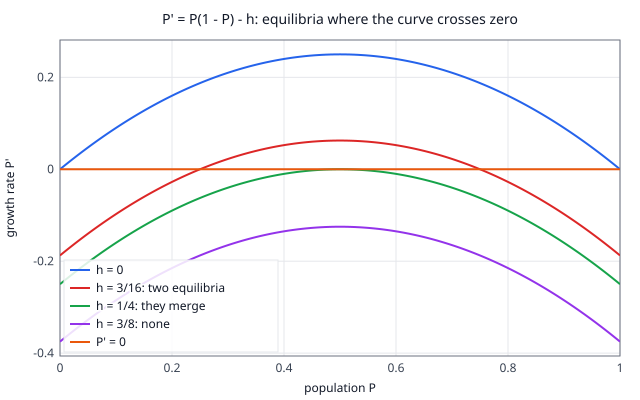

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [10]:
p = plot(P*(1 - P), P*(1 - P) - 3/16, P*(1 - P) - 1/4, P*(1 - P) - 3/8, 0, P, 0, 1);
p = legend(p, "h = 0", "h = 3/16: two equilibria", "h = 1/4: they merge", "h = 3/8: none", "P' = 0");
labels(title(p, "P' = P(1 - P) - h: equilibria where the curve crosses zero"), "population P", "growth rate P'")

As the fishing rate $h$ rises, the two equilibria move together, merge at $h = 1/4$ and disappear: for $h > 1/4$ every
population collapses. A small change in $h$ causes a sudden qualitative change, a **bifurcation**. Fisheries
managers worry about exactly this: the maximum sustainable yield $h = rK/4$ is also the edge of collapse.

**Try this.** Find the equilibria of $y' = y^2 - 4$ and decide which is stable. Sketch the phase line first, then
check with `solve` and `deriv`.

## 5. Blow-up and non-uniqueness

Two surprises that the slope field does not show. First, a solution can go to infinity in finite time:

In [11]:
dsolve(d(y, x) == y^2, y, x, 0, 1)

1/(1-x)

> Separable: y' = f(x) g(y) with f(x) = 1 and g(y) = y^2. Divide by g(y) and integrate both sides: ∫ dy/g(y) = ∫ f(x) dx, so -1/y = x + C1. Dividing by g(y) loses the constant solutions where g(y) = 0: y = 0. The start value y(0) = 1 fixes the constant: C1 = -1.

$y = 1/(1 - x)$ starts at 1 and is infinite at $x = 1$. The growth rate $y^2$ grows faster than $y$ itself, and the
solution runs away. (Compare $y' = y$, which only reaches $e^x$.)

Second, a solution need not be unique. $y' = \sqrt{y}$ with $y(0) = 0$ has the solution $y = 0$, but also:

In [12]:
dsolve(d(y, x) == sqrt(y), y, x, 0, 0)

x^2/4

> Separable: y' = f(x) g(y) with f(x) = 1 and g(y) = sqrt(y). Divide by g(y) and integrate both sides: ∫ dy/g(y) = ∫ f(x) dx, so 2*sqrt(y) = x + C1. The start value y(0) = 0 fixes the constant: C1 = 0.

Both $y = 0$ and $y = x^2/4$ (for $x \ge 0$) satisfy the equation and the start value; in fact $y$ can sit at 0 for any
time and then take off. The **existence and uniqueness theorem** (Picard–Lindelöf) says this cannot happen when $f$
and $\partial f/\partial y$ are continuous near the start point. Here $\partial f/\partial y = 1/(2\sqrt y)$ is
infinite at $y = 0$, which is where uniqueness fails. Physically, a model with non-unique solutions is missing
information.

**Try this.** Is the solution of $y' = x^2 + y^2$, $y(0) = 0$ unique? (Look at $f$ and $\partial f/\partial y$.)

## Summary

* A slope field draws $y' = f(x, y)$ as short segments; solutions are curves tangent to them.
* Separable equations: $\int dy/g(y) = \int f(x)\,dx + C$; watch for lost constant solutions.
* The logistic equation $P' = rP(1 - P/K)$ gives an S-curve to the carrying capacity $K$.
* For $y' = f(y)$: equilibria are the zeros of $f$, stable where $f' < 0$. Parameters can make equilibria merge and
  vanish (a bifurcation).
* Solutions can blow up in finite time, and are unique when $f$ and $\partial f/\partial y$ are continuous.

Next: [linear first-order equations](02-linear-first-order.ipynb), which can always be solved, with an integrating
factor.

## Exercises

1. **Slope field.** Draw the slope field of $y' = y(1 - y)$ for $0 \le x \le 4$, $-0.5 \le y \le 1.5$. Mark the
   equilibria and say which is stable.
2. **Separable.** Solve $y' = (1 + y^2)$ with $y(0) = 0$. Where does the solution blow up?
3. **Newton's cooling.** Coffee at 90 °C cools in a room at 20 °C by $T' = -(T - 20)/10$ (minutes). Solve, and find
   when it reaches 60 °C.
4. **Harvesting.** For $P' = P(1 - P) - h$, show by the quadratic formula that the equilibria exist exactly when
   $h \le 1/4$.
5. **Escape velocity.** A rocket's speed far from Earth obeys $v\,v' = -GM/r^2$ with $r$ as the independent variable:
   $v' = -GM/(r^2 v)$. Solve with $v(R) = v_0$ and find the $v_0$ for which $v \to 0$ as $r \to \infty$.

## Hints and answers

* **Section 1, Try this.** `fieldplot([1, y - x], x, -2, 3, y, -2, 3)`. $y = x + 1$ is a solution ($y' = 1 = y - x$);
  the others are $x + 1 + C_1e^x$ and run away from it.
* **Section 2, Try this.** $\int dy/y = \int \cos x\,dx$, $\log y = \sin x$, $y = e^{\sin x}$.
* **Section 3, Try this.** $1000/(1 + 9e^{-t/2}) = 900$ gives $e^{-t/2} = 1/81$, $t = 2\log 81 = 8\log 3 \approx 8.8$.
* **Section 4, Try this.** $y = \pm2$; $f'(y) = 2y$, so $y = -2$ is stable and $y = 2$ unstable.
* **Section 5, Try this.** $f = x^2 + y^2$ and $\partial f/\partial y = 2y$ are continuous everywhere: unique.
  (The solution exists only up to about $x = 2.0$, where it blows up.)
* **Exercise 1.** $y = 0$ unstable ($f'(0) = 1$), $y = 1$ stable ($f'(1) = -1$).
* **Exercise 2.** `dsolve(d(y, x) == 1 + y^2, y, x, 0, 0)` gives $\tan x$, which blows up at $x = \pi/2$.
* **Exercise 3.** $T = 20 + 70e^{-t/10}$; $60 = 20 + 70e^{-t/10}$ gives $t = 10\log(7/4) \approx 5.6$ minutes.
* **Exercise 4.** $P^2 - P + h = 0$ has $P = (1 \pm \sqrt{1 - 4h})/2$, real exactly when $h \le 1/4$.
* **Exercise 5.** $v^2/2 = GM/r + C$; $v^2 = v_0^2 - 2GM/R + 2GM/r$, which tends to $v_0^2 - 2GM/R$. Zero when
  $v_0 = \sqrt{2GM/R}$, the escape velocity (11.2 km/s for Earth).

## Sources

1. W. E. Boyce, R. C. DiPrima and D. B. Meade, *Elementary Differential Equations and Boundary Value Problems*, 11th
   ed., Wiley (2017), chapters 1 and 2.
2. S. H. Strogatz, *Nonlinear Dynamics and Chaos*, 2nd ed., Westview Press (2015), chapters 2 and 3 (phase lines,
   bifurcations, the fishery).
3. P.-F. Verhulst, "Notice sur la loi que la population suit dans son accroissement", *Correspondance mathématique et
   physique* 10 (1838) 113–121.
4. E. Lindelöf, "Sur l'application de la méthode des approximations successives aux équations différentielles
   ordinaires du premier ordre", *Comptes rendus de l'Académie des sciences* 116 (1894) 454–457.